In [2]:
import json
import numpy as np
from utils import DATA_DIR, ATTENTION_INTERVENTIONS_DIR, PLOT_DIR
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib.ticker import MaxNLocator, PercentFormatter
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

from utils import set_style, save_plot, PALETTE
set_style()

In [3]:
HEADS_DIR = ATTENTION_INTERVENTIONS_DIR / "heads"   # (examples, layers, heads)
LAYERS_DIR = ATTENTION_INTERVENTIONS_DIR / "layers"  # (examples, layers)
MODEL_DIR = ATTENTION_INTERVENTIONS_DIR / "model"   # (examples)

with open(DATA_DIR / "examples.json", "r") as f:
    examples = json.load(f)

In [27]:
id_index = {e["id"]: row
            for row, e in enumerate(examples)}


def load_effects(dir_path: Path, gender: str):
    return {"dir": np.load(dir_path / f"{gender}_direct.npy", mmap_mode="r"),
            "ind": np.load(dir_path / f"{gender}_indirect.npy", mmap_mode="r")}


def topk_indices(arr, k, gender):
    # ASSUMPTION: man logits signs flipped to negative.
    # plot_effect_summary shows that NIE for man is negative. I aim to plot the heads with have the strongest effects, regardless of direction
    # if gender == "woman":
        return np.abs(arr).argsort(axis=None)[-k:][::-1]   # most positive first
    # return arr.argsort(axis=None)[:k]          # most negative first

In [130]:

all_results = {}
SIGN = {"man": -1.0, "woman": 1.0}

for gender in ["man", "woman"]:
    heads = load_effects(HEADS_DIR, gender)
    layers = load_effects(LAYERS_DIR, gender)
    model = load_effects(MODEL_DIR, gender)

    s = SIGN[gender]

    results = []

    for ex in examples:
        if abs(float(ex["definitionality"])) <= 0.75:
            continue

        i = id_index[ex["id"]]

        a = ex["baseline_m"]["profession"]      # baseline prompt (no patching)
        d = ex["baseline_m"][gender]            # gendered prompt (no patching)

        r = {
            "profession": ex["profession"],
            "profession_context": ex["profession_context"],
            f"{gender}_context": ex[f"{gender}_context"],
            "include_in_total_effect_analysis": ex["include_in_total_effect_analysis"],
            "is_female_leaning": ex["is_female_leaning"],

            "profession_m": a,
            f"{gender}_m": d,

            # the saved files hold raw patched values, so subtract
            # the baseline `a` to turn them into effects (NIE = c - a, NDE = b - a)
            "ind_effect_head": s * (np.asarray(heads["ind"][i]) - a),
            "dir_effect_head": s * (np.asarray(heads["dir"][i]) - a),

            "ind_effect_layer": s * (np.asarray(layers["ind"][i]) - a),
            "dir_effect_layer": s * (np.asarray(layers["dir"][i]) - a),

            "ind_effect_model": s * (float(model["ind"][i]) - a),
            "dir_effect_model": s * (float(model["dir"][i]) - a),
        }
        r["total_effect"] = s * (d - a)
        r["residual"] = r["total_effect"] - \
            (r["dir_effect_model"] + r["ind_effect_model"])

        results.append(r)

    filtered = results

    metadata = {
        "mean_total_effect": np.mean([r["total_effect"] for r in filtered]),
        "mean_model_ind_effect": np.mean([r["ind_effect_model"] for r in filtered]),
        "mean_model_dir_effect": np.mean([r["dir_effect_model"] for r in filtered]),
        "mean_residual": np.mean([r["residual"] for r in filtered]),
    }
    
    print(f"n_examples: {len(results)}")

    all_results[gender] = {**metadata, "results": results}

n_examples: 187
n_examples: 187


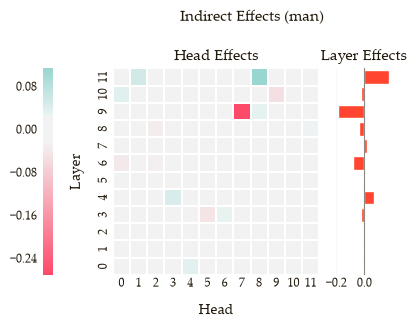

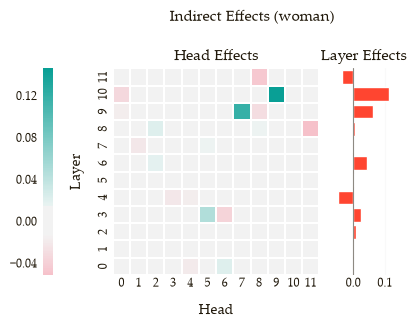

In [244]:
# codes adapted from https://github.com/sebastianGehrmann/CausalMediationAnalysis/blob/master/attention_figures1.py
"""
Creates figures for attention intervention analysis from JSON files:
    - Stacked bar chart with direct/indirect/total effects
    - Heatmap for head-level effects
    - Barplot for layer-level effects
    - Combined heatmap/barplot for head- and layer-level effects
"""

CMAP = sns.diverging_palette(5.82, 181.53, 99, 59., 25, as_cmap=True)
TICK_PAD = -4

C_L = {'ind': "Share of total effect",
       'dir': "Share of total effect lost"}

FULL = {"ind": "Indirect", "dir": "Direct"}


def plot_top_heads_stacked_bar(gender,
                               mean_ind_by_head,
                               mean_dir_by_head,
                               mean_te: float,
                               k,):
    
    # Select top k heads by indirect effect
    topk_inds = topk_indices(mean_ind_by_head, k, gender)

    plt.figure(figsize=(6, 3))
    topk_direct = []
    topk_indirect = []
    labels = []
    for ind in topk_inds:
        layer, head = np.unravel_index(ind, mean_ind_by_head.shape)
        topk_indirect.append(mean_ind_by_head[layer, head])
        topk_direct.append(mean_dir_by_head[layer, head])
        labels.append(f'{layer}-{head}')
    width = 0.6
    inds = range(k)

    p1 = plt.bar(inds, topk_direct, width, linewidth=0)
    p2 = plt.bar(inds, topk_indirect, width, bottom=topk_direct,
                 linewidth=0, color=PALETTE[1])
    p3 = plt.axhline(mean_te, linestyle='--', zorder=0)

    q = pd.DataFrame({"mean_te": mean_te,
                      "labels": labels,
                      "topk_direct": topk_direct,
                      "topk_indirect": topk_indirect}).sort_values("topk_indirect")
    q["gap"] = (q["topk_direct"] + q["topk_indirect"] -
                mean_te) / mean_te * 100
    print(q)

    ax = plt.gca()
    ax.tick_params(axis='x', pad=TICK_PAD)
    ax.set_ylabel("Effects (TE ≈ NDE + NIE)")
    ax.set_xlabel("Layer-Head")
    plt.gca().yaxis.set_major_locator(MaxNLocator(nbins=4))

    ax.set_title(f'Effects of top heads ({gender})')
    plt.xticks(inds, labels)
    plt.legend((p3, p2[0], p1[0]),
               ('TE', 'NDE', 'NIE'),
               loc='upper right',
               bbox_to_anchor=(.99, 0.90))
    sns.despine(left=True, bottom=True)

    folder_path = PLOT_DIR / 'attention_intervention/stacked_bar_charts'
    save_plot(f"{gender}", folder_path=folder_path)

    plt.show()
    plt.close()


def plot_head_effects(gender: str,
                      effect_type: str,
                      mean_effect: np.ndarray,
                      ax=None,
                      normalized=True):
    
    # Subplot or standalone configs
    subplot = True
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5))
        subplot = False

    title = ("Head Effects" if subplot
             else f'Mean {FULL[effect_type]} Effect ({gender})')
    cbar_pos = "left" if subplot else "right"
    cbar_pad = 0.6 if subplot else 0.1

    # Plot heatmap. Things shared across subplots or standalone
    divider = make_axes_locatable(ax)
    cax = divider.append_axes(cbar_pos, size="5%", pad=cbar_pad)

    sns.heatmap(mean_effect,
                square=True,
                cmap=CMAP,
                center=0,
                linewidths=0.005,
                ax=ax,
                cbar_ax=cax,)
    
    ax.tick_params(axis='both', which='major', pad=TICK_PAD)
    ax.invert_yaxis()

    cax.yaxis.set_label_position(cbar_pos)
    cax.yaxis.set_ticks_position(cbar_pos)

    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(length=0, pad=4)
    cbar.ax.yaxis.set_major_locator(MaxNLocator(5))
    if normalized:
        cbar.ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))

    ax.set(xlabel='Head', ylabel='Layer', title=title)

    if subplot:
        return

    # Standalone-only
    cbar.set_label(C_L[effect_type])

    folder_path = PLOT_DIR / \
        f'attention_intervention/heat_maps_{effect_type}'
    save_plot(f"{gender}_{'normalized' if normalized else ''}",
              folder_path=folder_path)

    plt.show()
    plt.close()


def plot_layer_effects(gender: str,
                       effect_type: str,
                       mean_effect: np.ndarray,
                       ax=None,
                       normalized=True):
    # print("LAYER EFFECTS")
    # print(mean_effect)
    # Subplot or standalone configs
    subplot = True
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 7))
        subplot = False
    title = ("Layer Effects" if subplot
             else f'Mean {FULL[effect_type]} Effect ({gender})')

    # Plot layer-level bar chart for indirect and direct effects
    # Plot barchart. Things shared across subplots or standalone
    ax.axvline(0, color="#1F1709", linewidth=0.8, alpha=0.5)
    sns.barplot(x=mean_effect,
                y=list(range(mean_effect.shape[0])),
                orient="h",
                ax=ax,
                saturation=1)
    sns.despine(left=True, bottom=True)
    ax.invert_yaxis()
    ax.tick_params(axis='both', which='major', pad=TICK_PAD)
    ax.set_title(title)

    if normalized:
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))

    if subplot:
        ax.set_yticklabels([])
        return

    ax.grid(axis='y')
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.set(ylabel='Layer',
           xlabel=C_L[effect_type])

    folder_path = PLOT_DIR / f'attention_intervention/layer_{effect_type}'
    save_plot(f"{gender}{'_normalized' if normalized else ''}",
              folder_path=folder_path)

    plt.show()
    plt.close()


def plot_combined_head_and_layer_effects(gender,
                                         effect_type: str,
                                         mean_head_effect,
                                         mean_layer_effect,
                                         normalized=True):
    fig, (ax1, ax2) = plt.subplots(ncols=2,
                                   figsize=(4.5, 4),
                                   gridspec_kw={'width_ratios': [5, 1],
                                                "wspace": 0.1},
                                   #    layout="constrained"
                                   )
    # print(gender)
    # head_sum = mean_head_effect.sum(axis=1)
    # print(np.abs(head_sum - mean_layer_effect).max())
    
    

    plot_head_effects(gender, effect_type, mean_head_effect, ax1, normalized)
    plot_layer_effects(gender, effect_type, mean_layer_effect, ax2, normalized)

    pos1 = ax1.get_position()
    pos2 = ax2.get_position()
    ax2.set_position([pos2.x0, pos1.y0, pos2.width, pos1.height])

    x = (pos1.x0 + pos2.x1) / 2
    fig.suptitle(f'{FULL[effect_type]} Effects ({gender})',
                 y=0.9,
                 x=x)

    folder_path = PLOT_DIR / f"heatmaps_w_bar_{effect_type}"
    save_plot(f"{gender}{'_normalized' if normalized else ''}",
              folder_path=folder_path)


def plot_effect_summary(gender,
                        ind_by_head: np.ndarray,
                        te: float,
                        nde_all,
                        nie_all):
    nie_sum = ind_by_head.sum(axis=(1, 2)).mean()

    df = pd.DataFrame({
        "effect": ["TE", "NDE-all", "NIE-all", "NIE-sum"],
        "value": [te, nde_all, nie_all, nie_sum]
    })

    plt.figure(figsize=(3, 4))
    ax = sns.barplot(data=df,
                     x="effect",
                     y="value",
                     saturation=1)
    sns.despine(left=True, bottom=True)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.set(ylabel="Effects", xlabel="", title=f"Effects Summary ({gender})")
    ax.tick_params(axis="both", which="major", pad=TICK_PAD)
    ax.axhline(0, color="#1F1709", linewidth=0.5, alpha=0.4)

    folder_path = PLOT_DIR / "effects_summary"
    save_plot(f"{gender}", folder_path=folder_path)

    plt.show()
    print({"te": te,
           "nde_all": nde_all,
           "nie_all": nie_all,
           "nie_sum": nie_sum,
           })


def plot_decomposition(gender: str,
                       ind: np.ndarray,
                       dir: np.ndarray,
                       te: np.ndarray,
                       hue: np.ndarray):
    s = ind + dir
    fig, ax = plt.subplots(figsize=(5, 5))
    sns.scatterplot(x=s,
                    y=te,
                    hue=np.where(hue == True, "Female Profession",
                                 "Male Profession"),
                    alpha=0.6)

    lo, hi = min(s.min(), te.min()), max(s.max(), te.max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="TE = NDE + NIE")

    ax.set_xlabel("NDE + NIE")
    ax.set_ylabel("TE")
    ax.set_title(f"TE ≈ NDE + NIE ({gender})")
    ax.set_aspect("equal")
    ax.legend()
    ax.tick_params(axis='both', which='major', pad=TICK_PAD)
    sns.despine(left=True, bottom=True)

    # Numbers
    print(gender)
    def gap(s, te): return (s.mean() - te.mean()) / te.mean() * 100
    print("Female profession:", gap(s[hue == True],  te[hue == True]))
    print("Male profession:",   gap(s[hue == False], te[hue == False]))

    folder_path = PLOT_DIR / "decomposition"
    save_plot(f"{gender}", folder_path=folder_path)


def save_figures(data, gender, k=10):

    # --- LOAD DATA FROM JSON OBJ ---
    results = data['results']
    df = pd.DataFrame(results)
    
    df = df[df["is_female_leaning"]]

    mean_te = data["mean_total_effect"]

    # --- AGGREGATE BY HEAD ---
    # Convert column to 3d ndarray (num_examples x num_layers x num_heads)
    ind_by_head = np.stack(df['ind_effect_head'].to_list())
    dir_by_head = np.stack(df['dir_effect_head'].to_list())

    # Average by head
    mean_ind_by_head = ind_by_head.mean(axis=0)
    mean_dir_by_head = dir_by_head.mean(axis=0)

    # # normalize
    # mean_ind_by_head_norm = mean_ind_by_head / mean_te
    # mean_dir_by_head_norm = (mean_dir_by_head - mean_te) / mean_te

    # --- AGGREGATE BY LAYER ---
    # Convert column to 2d ndarray (num_examples x num_layers)
    ind_by_layer = np.stack(df['ind_effect_layer'].to_list())
    dir_by_layer = np.stack(df['dir_effect_layer'].to_list())

    # Average by head
    mean_ind_by_layer = ind_by_layer.mean(axis=0)
    mean_dir_by_layer = dir_by_layer.mean(axis=0)

    # # normalize
    # mean_ind_by_layer_norm = mean_ind_by_layer / mean_te
    # mean_dir_by_layer_norm = (mean_dir_by_layer - mean_te) / mean_te

    # --- PLOT FIGURES ---
    # plot_effect_summary(gender,
    #                     ind_by_head=ind_by_head,
    #                     te=mean_te,
    #                     nde_all=data["mean_model_dir_effect"],
    #                     nie_all=data["mean_model_ind_effect"]
    #                     )

    # plot_top_heads_stacked_bar(gender,
    #                            mean_ind_by_head,
    #                            mean_dir_by_head,
    #                            mean_te,
    #                            k)

    # plot_decomposition(gender,
    #                    np.stack(df['ind_effect_model'].to_list()),
    #                    np.stack(df['dir_effect_model'].to_list()),
    #                    np.stack(df['total_effect'].to_list()),
    #                    np.stack(df["is_female_leaning"].to_list())
    #                    )

    # plot_head_effects(gender, "ind", mean_ind_by_head_norm)
    # plot_head_effects(gender, "dir", mean_dir_by_head_norm)

    # plot_layer_effects(gender, "ind", mean_ind_by_layer_norm)
    # plot_layer_effects(gender, "dir", mean_dir_by_layer_norm)
    
    
    
    plot_combined_head_and_layer_effects(gender,
                                         "ind",
                                         mean_ind_by_head,
                                         mean_ind_by_layer,
                                         normalized=False)
    # plot_combined_head_and_layer_effects(gender,
    #                                      "dir",
    #                                      mean_dir_by_head,
    #                                      mean_dir_by_layer,
    #                                      normalized=False)


for g in ["man", "woman"]:
    save_figures(all_results[g], g)

In [247]:
T = True
str(T)

'True'

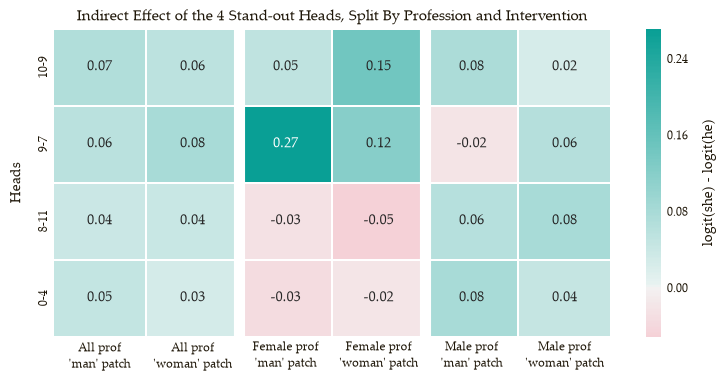

In [278]:
LEAN = {"True": "Female prof",
        "all": "All prof",
        "False": "Male prof"}

def extract_head_effects(all_results, heads):
    """Rows: heads. Columns: FL man, FL woman, ML man, ML woman.
    Values are raw logit(she) - logit(he): the man swap is sign-flipped."""
    columns, col_labels = [], []
    for female_leaning in ("all", True, False):
        for gender, sign in (("man", -1), ("woman", 1)):
            df = pd.DataFrame(all_results[gender]["results"])
            if isinstance(female_leaning, bool):
                df = df[df["is_female_leaning"] == female_leaning]
            mean_by_head = np.stack(
                df["ind_effect_head"].to_list()).mean(axis=0)
            columns.append([sign * mean_by_head[layer, head]
                           for layer, head in heads])
            lean = LEAN[str(female_leaning)]
            col_labels.append(f"{lean}\n'{gender}' patch")

    row_labels = [f"{layer}-{head}" for layer, head in heads]
    return np.array(columns).T, row_labels, col_labels


HEADS = [(10, 9), (9, 7), (8, 11), (0, 4)]
matrix, head_labels, cond_labels = extract_head_effects(all_results, HEADS)


cmap = sns.diverging_palette(
    5.82, 181.53, 99, 59., 1, n=2, as_cmap=True)

fig, ax = plt.subplots(figsize=(9, 4))

sns.heatmap(matrix,
            annot=True,
            fmt=".2f",
            annot_kws={"size": 10},
            cmap=cmap,
            center=0,
            xticklabels=cond_labels,
            yticklabels=head_labels,
            linewidths=0.1,
            cbar_kws={"label": "logit(she) - logit(he)"},
            ax=ax)

ax.set(ylabel="Heads",
       title="Indirect Effect of the 4 Stand-out Heads, Split By Profession and Intervention")
ax.tick_params(axis='both', which='major', pad=TICK_PAD)

for i in (2, 4):    
    ax.axvline(i, color="white", linewidth=8)

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(length=0, pad=4)
cbar.ax.yaxis.set_major_locator(MaxNLocator(5))

save_plot("ind_effect_top_heads")
plt.show()


In [277]:
# Sum of Heads in a Layer equal to layer effects?

for g, data in all_results.items():
    print(g)
    df = pd.DataFrame(data["results"])

    head_means = np.stack(df['ind_effect_head'].to_list()).mean(axis=0)
    layer_means = np.stack(df['ind_effect_layer'].to_list()).mean(axis=0)

    head_sum = head_means.sum(axis=1)
    print(np.abs(head_sum - layer_means).max())

man
0.00095384195
woman
0.0011200719
